# Part 2 baseline pipeline (Poushali)

Team 16, DATA 266 Lab 2. This notebook is my own version of it, written separately from the team notebook `p2_finetune_team16.ipynb`.

What is different from the team runs: my own training loop (no `train_text_to_image_lora.py`), my own cleaning and duplicate check, and LoRA rank 8. What is kept the same so the numbers can be compared: dataset, 90/10 split with seed 266, 512x512, 750 optimizer steps, learning rate 1e-4, batch 1 x 4 accumulation, fp16, the 20 committed prompts in `eval/p2_prompts.csv`, seeds 0 and 1, DPM-Solver 25 steps, guidance 7.5.

In [1]:
import os
os.environ["GITHUB_TOKEN"] = "<redacted>"
os.environ["HF_TOKEN"] = "<redacted>"

In [2]:
import os, subprocess
REPO = "github.com/sadaffatimaee/data266-lab2-team16.git"
if subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True).returncode != 0 and os.path.isdir("/kaggle"):
    try:
        from kaggle_secrets import UserSecretsClient
        token = os.environ.get("GITHUB_TOKEN") or UserSecretsClient().get_secret("GITHUB_TOKEN")
        subprocess.run(["git", "clone", "-q", f"https://{token}@{REPO}", "/tmp/repo"], check=True)
        subprocess.run(["git", "-C", "/tmp/repo", "remote", "set-url", "origin", f"https://{REPO}"], check=True)
        os.chdir("/tmp/repo")
    except Exception as e:
        print("repository not cloned:", type(e).__name__)
ROOT = subprocess.run(["git", "rev-parse", "--show-toplevel"], capture_output=True, text=True).stdout.strip()

import subprocess, sys, random, numpy as np, torch
SEED = 266; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True,
text=True).stdout.strip()
print({"commit": commit, "python": sys.version.split()[0], "torch": torch.__version__,
"gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", "seed": SEED})

{'commit': 'f94d910', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'gpu': 'Tesla T4', 'seed': 266}


In [3]:
import importlib.metadata as md
if os.path.isdir("/kaggle"):
    subprocess.run("pip install -q -U diffusers peft torchmetrics torch-fidelity lpips && pip uninstall -y -q torchao", shell=True)

def version(m):
    try:
        return md.version(m)
    except md.PackageNotFoundError:
        return "not installed"

print({m: version(m) for m in ['torch', 'diffusers', 'peft', 'transformers', 'datasets', 'torchmetrics', 'torch-fidelity', 'lpips', 'huggingface_hub', 'pandas', 'pillow', 'numpy']})

{'torch': '2.11.0+cu130', 'diffusers': '0.42.1', 'peft': '0.21.2', 'transformers': '5.20.2', 'datasets': '4.8.5', 'torchmetrics': '1.9.0', 'torch-fidelity': '0.4.0', 'lpips': '0.1.4', 'huggingface_hub': '1.33.0', 'pandas': '2.3.3', 'pillow': '13.0.0', 'numpy': '2.1.3'}


In [4]:
import json, time, glob, io, hashlib
import pandas as pd
from PIL import Image, ImageOps

SMOKE = os.environ.get("P2_SMOKE", "0") == "1"
DEV = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEV == "cuda" else torch.float32
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else os.path.join(ROOT or os.getcwd(), "work_p2")
BASE = "hf-internal-testing/tiny-stable-diffusion-torch" if SMOKE else "stable-diffusion-v1-5/stable-diffusion-v1-5"
DATASET = "lambdalabs/naruto-blip-captions"
RES = 64 if SMOKE else 512
RANK = 8
LR = 1e-4
STEPS = 2 if SMOKE else 750
BATCH, ACCUM = 1, (1 if SMOKE else 4)
GEN = dict(num_inference_steps=2 if SMOKE else 25, guidance_scale=7.5, height=RES, width=RES)
RUN = "poushali_lora_r8"
os.makedirs(WORK, exist_ok=True)

def secret(name):
    if os.environ.get(name):
        return os.environ[name]
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(name)
    except Exception:
        return None

HF_TOKEN = secret("HF_TOKEN")
print({"smoke": SMOKE, "device": DEV, "work": WORK, "base": BASE, "rank": RANK, "steps": STEPS,
       "batch": f"{BATCH} x {ACCUM}", "hf_token": bool(HF_TOKEN)})

{'smoke': False, 'device': 'cuda', 'work': '/kaggle/working', 'base': 'stable-diffusion-v1-5/stable-diffusion-v1-5', 'rank': 8, 'steps': 750, 'batch': '1 x 4', 'hf_token': True}


## 2.1 Data preparation
I decode every image, drop unreadable files, very small images and empty captions, then drop exact duplicates (same pixels) and near duplicates (same 16x16 grayscale thumbnail). The split is a seed-266 shuffle, 10% test.

In [5]:
from datasets import load_dataset, Image as HFImage

raw = load_dataset(DATASET, split="train").cast_column("image", HFImage(decode=False))
if SMOKE:
    raw = raw.select(range(60))

kept, exact, near = [], set(), set()
bad = dup = 0
for r in raw:
    try:
        data = r["image"]["bytes"] or open(r["image"]["path"], "rb").read()
        im = Image.open(io.BytesIO(data))
        im.load()
        im = im.convert("RGB")
        cap = str(r["text"]).strip()
        if min(im.size) < 64 or not cap:
            raise ValueError
    except Exception:
        bad += 1
        continue
    h1 = hashlib.sha1(im.tobytes()).hexdigest()
    h2 = hashlib.sha1(im.convert("L").resize((16, 16)).tobytes()).hexdigest()
    if h1 in exact or h2 in near:
        dup += 1
        continue
    exact.add(h1); near.add(h2)
    kept.append((im, cap))
print(f"loaded {len(raw)} | unreadable or invalid removed: {bad} | duplicates removed: {dup} | kept: {len(kept)}")

order = list(range(len(kept)))
random.Random(SEED).shuffle(order)
n_test = round(0.10 * len(kept))
split = {"test": order[:n_test], "train": order[n_test:]}
items = {}
for name, ids in split.items():
    d = f"{WORK}/data/{name}"
    os.makedirs(d, exist_ok=True)
    items[name] = []
    for k, i in enumerate(ids):
        im, cap = kept[i]
        fn = f"{d}/{name}_{k:04d}.png"
        ImageOps.fit(im, (RES, RES), Image.Resampling.BICUBIC).save(fn)
        items[name].append((fn, cap))
    print(f"{name}: {len(ids)} images at {RES}x{RES}")

caps = [c for _, c in kept]
words = pd.Series(" ".join(caps).lower().split()).value_counts()
print("mean caption length (words):", round(np.mean([len(c.split()) for c in caps]), 1))
print("captions with 'man':", sum(" man " in f" {c.lower()} " for c in caps),
      "| with 'woman':", sum(" woman " in f" {c.lower()} " for c in caps))
print("top words:", words.head(15).to_dict())

README.md:   0%|          | 0.00/1.02k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/897 [00:00<?, ?B/s]

data/train-00000-of-00002-12944970063701(…): reconstructing file:   0%|          |  0.00B /  344MB            

data/train-00000-of-00002-12944970063701(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-cefa2f480689f1(…): reconstructing file:   0%|          |  0.00B /  357MB            

data/train-00001-of-00002-cefa2f480689f1(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1221 [00:00<?, ? examples/s]

loaded 1221 | unreadable or invalid removed: 0 | duplicates removed: 0 | kept: 1221
test: 122 images at 512x512
train: 1099 images at 512x512
mean caption length (words): 8.9
captions with 'man': 690 | with 'woman': 175
top words: {'a': 2302, 'with': 905, 'and': 740, 'man': 692, 'in': 537, 'hair': 464, 'white': 192, 'shirt': 192, 'eyes': 181, 'long': 181, 'black': 180, 'woman': 175, 'his': 163, 'on': 145, 'green': 142}


## 2.2 Fine-tuning: my own LoRA training loop
The base model is frozen. LoRA adapters (rank 8, alpha 8) are added to the UNet attention projections (`to_q`, `to_k`, `to_v`, `to_out.0`). Each step encodes images with the VAE, adds noise at a random timestep and trains the UNet to predict that noise (MSE). The adapters are kept in fp32 while the frozen weights run in fp16 with a gradient scaler.

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  492MB            

... (9 outputs left out)

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

There are modules in UNet2DConditionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

trainable parameters: 1594368
step 50/750 | loss (mean of last 50) 0.0985 | 101s
step 100/750 | loss (mean of last 50) 0.0900 | 199s
step 150/750 | loss (mean of last 50) 0.0906 | 297s
step 200/750 | loss (mean of last 50) 0.0855 | 394s
step 250/750 | loss (mean of last 50) 0.0789 | 492s
step 300/750 | loss (mean of last 50) 0.0981 | 590s
step 350/750 | loss (mean of last 50) 0.0860 | 688s
step 400/750 | loss (mean of last 50) 0.0832 | 786s
step 450/750 | loss (mean of last 50) 0.0867 | 884s
step 500/750 | loss (mean of last 50) 0.0968 | 982s
step 550/750 | loss (mean of last 50) 0.0924 | 1079s
step 600/750 | loss (mean of last 50) 0.0899 | 1177s
step 650/750 | loss (mean of last 50) 0.0955 | 1275s
step 700/750 | loss (mean of last 50) 0.0868 | 1372s
step 750/750 | loss (mean of last 50) 0.0756 | 1470s
{'run': 'poushali_lora_r8', 'method': 'LoRA rank 8 (own training loop)', 'trainable params': 1594368, 'learning rate': 0.0001, 'steps': 750, 'batch size': '1 x 4 grad-accum = 4', 'peak G

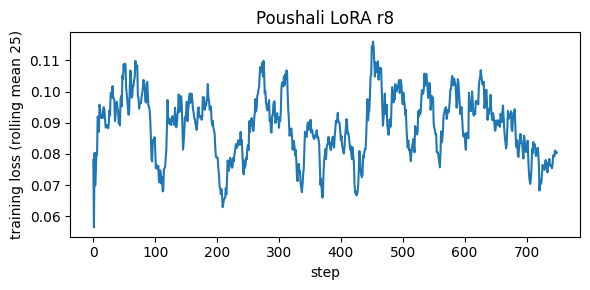

In [6]:
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, StableDiffusionPipeline
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict

tok = CLIPTokenizer.from_pretrained(BASE, subfolder="tokenizer")
text_enc = CLIPTextModel.from_pretrained(BASE, subfolder="text_encoder").to(DEV, DTYPE).requires_grad_(False)
vae = AutoencoderKL.from_pretrained(BASE, subfolder="vae").to(DEV, DTYPE).requires_grad_(False)
unet = UNet2DConditionModel.from_pretrained(BASE, subfolder="unet").to(DEV, DTYPE).requires_grad_(False)
noise_sched = DDPMScheduler.from_pretrained(BASE, subfolder="scheduler")
unet.add_adapter(LoraConfig(r=RANK, lora_alpha=RANK, init_lora_weights="gaussian",
                            target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
for p in unet.parameters():
    if p.requires_grad:
        p.data = p.data.float()
unet.enable_gradient_checkpointing()
params = [p for p in unet.parameters() if p.requires_grad]
n_trainable = sum(p.numel() for p in params)
print("trainable parameters:", n_trainable)

def to_tensor(path, flip):
    im = Image.open(path).convert("RGB")
    if flip:
        im = ImageOps.mirror(im)
    return torch.from_numpy(np.array(im)).permute(2, 0, 1).float() / 127.5 - 1

rng = random.Random(SEED)
train_items = items["train"]
def batches():
    while True:
        order = list(range(len(train_items)))
        rng.shuffle(order)
        for i in range(0, len(order) - BATCH + 1, BATCH):
            chunk = [train_items[j] for j in order[i:i + BATCH]]
            px = torch.stack([to_tensor(p, rng.random() < 0.5) for p, _ in chunk])
            ids = tok([c for _, c in chunk], padding="max_length", max_length=tok.model_max_length,
                      truncation=True, return_tensors="pt").input_ids
            yield px, ids

opt = torch.optim.AdamW(params, lr=LR, weight_decay=1e-2)
scaler = torch.amp.GradScaler("cuda", enabled=DEV == "cuda")
gen_t = torch.Generator(DEV).manual_seed(SEED)
stream = batches()
losses = []
if DEV == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
unet.train()
for step in range(1, STEPS + 1):
    step_loss = 0.0
    for _ in range(ACCUM):
        px, ids = next(stream)
        with torch.no_grad():
            lat = vae.encode(px.to(DEV, DTYPE)).latent_dist.sample() * vae.config.scaling_factor
            cond = text_enc(ids.to(DEV))[0]
        noise = torch.randn(lat.shape, generator=gen_t, device=DEV, dtype=lat.dtype)
        t = torch.randint(0, noise_sched.config.num_train_timesteps, (lat.shape[0],), generator=gen_t, device=DEV)
        noisy = noise_sched.add_noise(lat, noise, t)
        with torch.autocast(DEV, dtype=torch.float16, enabled=DEV == "cuda"):
            pred = unet(noisy, t, cond).sample
        loss = torch.nn.functional.mse_loss(pred.float(), noise.float()) / ACCUM
        scaler.scale(loss).backward()
        step_loss += loss.item()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(params, 1.0)
    scaler.step(opt)
    scaler.update()
    opt.zero_grad(set_to_none=True)
    losses.append(step_loss)
    if step % 50 == 0 or step == STEPS:
        print(f"step {step}/{STEPS} | loss (mean of last 50) {np.mean(losses[-50:]):.4f} | {time.time() - t0:.0f}s", flush=True)
train_secs = time.time() - t0
peak_gb = torch.cuda.max_memory_allocated() / 1e9 if DEV == "cuda" else 0.0

LORA_DIR = f"{WORK}/{RUN}"
StableDiffusionPipeline.save_lora_weights(LORA_DIR, unet_lora_layers=convert_state_dict_to_diffusers(get_peft_model_state_dict(unet)),
                                          safe_serialization=True)
train_stats = {"run": RUN, "method": f"LoRA rank {RANK} (own training loop)", "trainable params": n_trainable,
               "learning rate": LR, "steps": STEPS, "batch size": f"{BATCH} x {ACCUM} grad-accum = {BATCH * ACCUM}",
               "peak GPU memory (GB)": round(peak_gb, 2), "training time (min)": round(train_secs / 60, 1),
               "GPU-hours": round(train_secs / 3600, 3)}
json.dump(train_stats, open(f"{LORA_DIR}/train_stats.json", "w"), indent=1)
print(train_stats)

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 3))
plt.plot(pd.Series(losses).rolling(25, min_periods=1).mean())
plt.xlabel("step"); plt.ylabel("training loss (rolling mean 25)"); plt.title("Poushali LoRA r8")
plt.tight_layout(); plt.savefig(f"{WORK}/p2_poushali_loss.png", dpi=120); plt.show()
del unet, text_enc, vae, opt
if DEV == "cuda":
    torch.cuda.empty_cache()

## 2.3 Image generation
The 20 prompts come from the committed file `eval/p2_prompts.csv` (10 in-domain from test captions, 5 out-of-domain, 5 compositional). The base model and my run use the same sampler settings and seeds 0 and 1.

20 prompts from /tmp/repo/eval/p2_prompts.csv


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


80 images | {'base': 40, 'poushali_lora_r8': 40} | NSFW-flagged: {'base': 0, 'poushali_lora_r8': 3} | median seconds per image: 4.38
columns: base | my LoRA r8   rows: ['P01', 'P03', 'P06', 'P08', 'P11', 'P14', 'P16', 'P17']


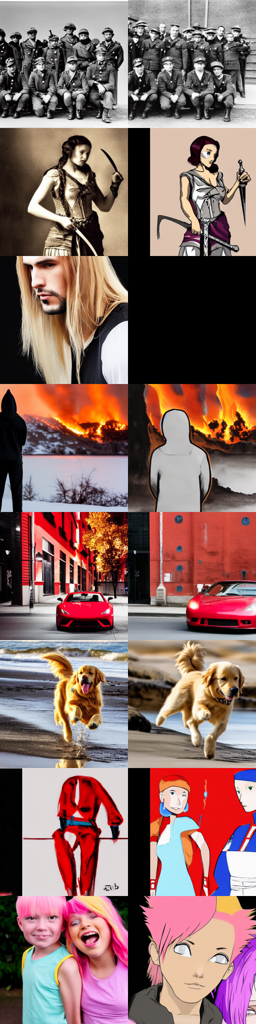

In [7]:
from diffusers import DPMSolverMultistepScheduler

ppath = os.path.join(ROOT, "eval", "p2_prompts.csv") if ROOT else ""
if not os.path.exists(ppath):
    ppath = glob.glob("/kaggle/input/**/p2_prompts.csv", recursive=True)[0]
P = pd.read_csv(ppath)
if SMOKE:
    P = P[P["pid"].isin(["P01", "P02", "P11", "P16"])]
print(len(P), "prompts from", ppath)

pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=DTYPE).to(DEV)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)
MODELS = {"base": None, RUN: LORA_DIR}
rows, gen_secs = [], []
for model, lora in MODELS.items():
    pipe.unload_lora_weights()
    if lora:
        pipe.load_lora_weights(lora)
    os.makedirs(f"{WORK}/gen/{model}", exist_ok=True)
    for _, r in P.iterrows():
        for seed in (0, 1):
            t1 = time.time()
            out = pipe(r["prompt"], generator=torch.Generator(DEV).manual_seed(seed), **GEN)
            gen_secs.append(time.time() - t1)
            fn = f"gen/{model}/{r['pid']}_seed{seed}.png"
            out.images[0].save(f"{WORK}/{fn}")
            flagged = bool(out.nsfw_content_detected[0]) if out.nsfw_content_detected else False
            rows.append({"file_name": fn[4:], "model": model, "pid": r["pid"], "type": r["type"], "prompt": r["prompt"],
                         "seed": seed, "nsfw_flagged": flagged, "sampler": "DPMSolverMultistep", **GEN})
gen = pd.DataFrame(rows)
gen.to_csv(f"{WORK}/gen/metadata.csv", index=False)
print(len(gen), "images |", gen.groupby("model").size().to_dict(), "| NSFW-flagged:", gen.groupby("model")["nsfw_flagged"].sum().to_dict(),
      "| median seconds per image:", round(float(np.median(gen_secs)), 2))

GRID = [p for p in ["P01", "P03", "P06", "P08", "P11", "P14", "P16", "P17"] if p in set(P["pid"])]
S = 256
grid = Image.new("RGB", (S * len(MODELS), S * len(GRID)), "white")
for i, pid in enumerate(GRID):
    for j, m in enumerate(MODELS):
        grid.paste(Image.open(f"{WORK}/gen/{m}/{pid}_seed0.png").convert("RGB").resize((S, S)), (j * S, i * S))
grid.save(f"{WORK}/gen/grid_poushali.png")
print("columns: base | my LoRA r8   rows:", GRID)
display(grid.resize((grid.width // 2, grid.height // 2)))
del pipe
if DEV == "cuda":
    torch.cuda.empty_cache()

## 2.4 Evaluation
Primary: KID between in-domain generations and the test images, and CLIP score (100 x cosine of `openai/clip-vit-base-patch16` embeddings). Secondary: LPIPS (AlexNet) between the two seeds of each prompt. Efficiency: GPU-hours and peak memory from training. Safety: the NSFW checker of the pipeline and a memorization check against the training images.

In [8]:
import lpips
from torchmetrics.image.kid import KernelInceptionDistance
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch16").to(DEV).eval()
cproc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch16")

@torch.no_grad()
def img_emb(ims, bs=32):
    out = []
    for i in range(0, len(ims), bs):
        px = cproc(images=ims[i:i + bs], return_tensors="pt")["pixel_values"].to(DEV)
        e = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
        out.append(e / e.norm(dim=-1, keepdim=True))
    return torch.cat(out)

@torch.no_grad()
def txt_emb(txts):
    t = cproc(text=txts, return_tensors="pt", padding=True, truncation=True).to(DEV)
    e = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
    return e / e.norm(dim=-1, keepdim=True)

def load(fn, size=None):
    im = Image.open(fn).convert("RGB")
    return im.resize((size, size), Image.Resampling.BICUBIC) if size else im

def u8(ims):
    return torch.stack([torch.from_numpy(np.array(i)).permute(2, 0, 1) for i in ims])

lp = lpips.LPIPS(net="alex", verbose=False).to(DEV)
def lp_t(im):
    return (torch.from_numpy(np.array(im)).permute(2, 0, 1).float() / 127.5 - 1).unsqueeze(0).to(DEV)

test_u8 = u8([load(f, 299) for f, _ in items["test"]])
results = {}
for model in MODELS:
    g = gen[gen["model"] == model]
    ims = [load(f"{WORK}/gen/{f}") for f in g["file_name"]]
    cs = (100 * (img_emb(ims) * txt_emb(list(g["prompt"]))).sum(-1).clamp(min=0)).cpu().numpy()
    g = g.assign(clip=cs)
    ind = [load(f"{WORK}/gen/{f}", 299) for f in g[g["type"] == "in_domain"]["file_name"]]
    torch.manual_seed(SEED)
    kid = KernelInceptionDistance(subset_size=min(20, len(ind)), subsets=50).to(DEV)
    kid.update(test_u8.to(DEV), real=True)
    kid.update(u8(ind).to(DEV), real=False)
    km, ks = kid.compute()
    with torch.no_grad():
        div = [lp(lp_t(load(f"{WORK}/gen/{model}/{pid}_seed0.png")), lp_t(load(f"{WORK}/gen/{model}/{pid}_seed1.png"))).item()
               for pid in g["pid"].unique()]
    results[model] = {"KID in-domain (mean)": round(km.item(), 4), "KID std": round(ks.item(), 4),
                      "CLIP score (all)": round(float(cs.mean()), 2),
                      **{f"CLIP {t}": round(float(v), 2) for t, v in g.groupby("type")["clip"].mean().items()},
                      "LPIPS diversity": round(float(np.mean(div)), 4), "NSFW-flagged": int(g["nsfw_flagged"].sum())}
results[RUN].update({"trainable params": n_trainable, "peak GPU memory (GB)": train_stats["peak GPU memory (GB)"],
                     "GPU-hours (training)": train_stats["GPU-hours"]})
table = pd.DataFrame(results).T
print("PART 2 BASELINE PIPELINE RESULTS (base model vs my LoRA r8)")
print(table.to_string())
print("RESULTS_JSON", json.dumps({"train": train_stats, "eval": results}))

config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

model.safetensors: downloading bytes:           |  0.00B            

... (6 outputs left out)

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 234MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:03<00:00, 31.0MB/s]
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)


PART 2 BASELINE PIPELINE RESULTS (base model vs my LoRA r8)
                  KID in-domain (mean)  KID std  CLIP score (all)  CLIP compositional  CLIP in_domain  CLIP out_of_domain  LPIPS diversity  NSFW-flagged  trainable params  peak GPU memory (GB)  GPU-hours (training)
base                            0.1361   0.0104             32.22               32.34           32.19               32.16           0.7717           0.0               NaN                   NaN                   NaN
poushali_lora_r8                0.0619   0.0077             30.80               33.35           29.65               30.56           0.7382           3.0         1594368.0                  2.61                 0.408
RESULTS_JSON {"train": {"run": "poushali_lora_r8", "method": "LoRA rank 8 (own training loop)", "trainable params": 1594368, "learning rate": 0.0001, "steps": 750, "batch size": "1 x 4 grad-accum = 4", "peak GPU memory (GB)": 2.61, "training time (min)": 24.5, "GPU-hours": 0.408}, "eval": {"bas

### Memorization check
For the 10 in-domain prompts (seed 0) of my run, I find the training image with the highest CLIP image similarity and show the 3 closest pairs.

highest CLIP similarity to any training image: [0.515, 0.772, 0.761, 0.681, 0.746, 0.713, 0.771, 0.725, 0.713, 0.777]
  pair 1: P10 vs train_0537.png (similarity 0.777)
  pair 2: P02 vs train_0244.png (similarity 0.772)
  pair 3: P07 vs train_0244.png (similarity 0.771)
left = generated, right = closest training image


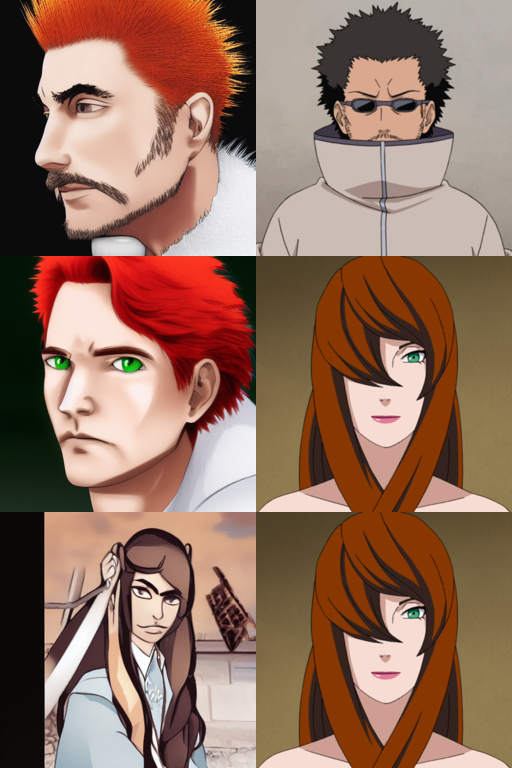

RESULTS_JSON {"memorization_max_sim": [0.515, 0.772, 0.761, 0.681, 0.746, 0.713, 0.771, 0.725, 0.713, 0.777], "memorization_mean": 0.717}


In [9]:
train_paths = [p for p, _ in items["train"]]
train_e = torch.cat([img_emb([load(p) for p in train_paths[i:i + 64]]) for i in range(0, len(train_paths), 64)])
g = gen[(gen["model"] == RUN) & (gen["type"] == "in_domain") & (gen["seed"] == 0)]
ge = img_emb([load(f"{WORK}/gen/{f}") for f in g["file_name"]])
sim = ge @ train_e.T
best, idx = sim.max(dim=1)
print("highest CLIP similarity to any training image:", [round(v, 3) for v in best.tolist()])
top = best.argsort(descending=True)[:3].tolist()
S = 256
sheet = Image.new("RGB", (2 * S, S * len(top)), "white")
for r, k in enumerate(top):
    print(f"  pair {r + 1}: {g['pid'].iloc[k]} vs {os.path.basename(train_paths[idx[k]])} (similarity {best[k]:.3f})")
    sheet.paste(load(f"{WORK}/gen/{g['file_name'].iloc[k]}").resize((S, S)), (0, r * S))
    sheet.paste(load(train_paths[idx[k]]).resize((S, S)), (S, r * S))
sheet.save(f"{WORK}/gen/memorization_poushali.png")
print("left = generated, right = closest training image")
display(sheet)
print("RESULTS_JSON", json.dumps({"memorization_max_sim": [round(v, 3) for v in best.tolist()],
                                  "memorization_mean": round(best.mean().item(), 3)}))

## Upload to Hugging Face
The LoRA weights and all generated images (with prompt, seed and model in `metadata.csv`) go to my Hugging Face account. Weights never go to GitHub.

In [10]:
if HF_TOKEN and not SMOKE:
    from huggingface_hub import HfApi
    api = HfApi(token=HF_TOKEN)
    user = api.whoami()["name"]
    repo = f"{user}/naruto-sd15-poushali-lora-r8"
    r = results[RUN]
    card = f"""---
base_model: {BASE}
library_name: diffusers
tags: [lora, stable-diffusion, text-to-image, naruto]
license: other
---
# Naruto-style LoRA rank 8 for Stable Diffusion 1.5 (Poushali baseline, Team 16)

DATA 266 Lab 2, Part 2. Non-commercial research and teaching use only (Naruto characters are copyrighted).

Base model `{BASE}` at 512x512. Data `{DATASET}`, {len(kept)} images after cleaning, seed {SEED} 90/10 split
({len(items['train'])} train / {len(items['test'])} test). Own training loop, LoRA rank {RANK} on UNet attention,
{n_trainable:,} trainable parameters, learning rate {LR}, {STEPS} steps, batch {BATCH} x {ACCUM}, fp16.
Peak GPU memory {train_stats['peak GPU memory (GB)']} GB, {train_stats['GPU-hours']} GPU-hours.

Results on 20 fixed prompts x 2 seeds: KID {r['KID in-domain (mean)']} +/- {r['KID std']}, CLIP score {r['CLIP score (all)']},
LPIPS diversity {r['LPIPS diversity']}. Limitations: weak on out-of-domain prompts, short BLIP captions, copyrighted style.
"""
    open(f"{LORA_DIR}/README.md", "w").write(card)
    api.create_repo(repo, exist_ok=True)
    api.upload_folder(folder_path=LORA_DIR, repo_id=repo)
    ds = f"{user}/naruto-poushali-generations"
    api.create_repo(ds, repo_type="dataset", exist_ok=True)
    api.upload_folder(folder_path=f"{WORK}/gen", repo_id=ds, repo_type="dataset")
    print("model:", f"https://huggingface.co/{repo}")
    print("images:", f"https://huggingface.co/datasets/{ds}")
else:
    print("upload skipped (smoke run or no HF_TOKEN)")

model: https://huggingface.co/Poushali0220/naruto-sd15-poushali-lora-r8
images: https://huggingface.co/datasets/Poushali0220/naruto-poushali-generations
